# 00 Check setup

This notebook only checks that everything works: Python packages, the predictions file, and plotting.

**Data: FAKE predictions** made by `make_fake_predictions.py`. Nothing here is a result.

In [1]:
import matplotlib.pyplot as plt
from common import load_predictions, RISING_THRESHOLD

df = load_predictions()
print(f"{len(df):,} rows loaded")

38,280 rows loaded


## The first rows

One row = one forecast: for one style (`item`), made in one week (`date`), for one horizon (4 or 8 weeks ahead), by one model.
The last two columns were added by `load_predictions()`: growth = 4-week average ÷ last 4-week average.

In [2]:
df.head()

,date,item,horizon,actual,predicted,model,period,last4_avg,category,predicted_rising,actually_rose,origin,predicted_growth,actual_growth
0,2025-01-05,skinny jeans,4,45.56,44.72,lightgbm,test,51.32,Jeans and denim,0,0,2025-01-05,0.871395,0.887763
1,2025-01-05,skinny jeans,4,45.56,49.60,last_value,test,51.32,Jeans and denim,0,0,2025-01-05,0.966485,0.887763
2,2025-01-05,skinny jeans,4,45.56,51.32,four_week_avg,test,51.32,Jeans and denim,0,0,2025-01-05,1.000000,0.887763
3,2025-01-05,skinny jeans,4,45.56,47.55,seasonal_naive,test,51.32,Jeans and denim,0,0,2025-01-05,0.926539,0.887763
4,2025-01-12,skinny jeans,4,46.06,41.06,lightgbm,test,48.33,Jeans and denim,0,0,2025-01-12,0.849576,0.953031


## What the file contains

In [3]:
print("Models:  ", sorted(df["model"].unique()))
print("Horizons:", sorted(df["horizon"].unique().tolist()))
print("Styles:  ", df["item"].nunique())
print("Weeks:   ", df["origin"].min().date(), "to", df["origin"].max().date())

Models:   ['four_week_avg', 'last_value', 'lightgbm', 'seasonal_naive']
Horizons: [4, 8]
Styles:   55
Weeks:    2025-01-05 to 2026-09-13


## One style, one picture

Predicted and actual growth for one style. Above the dashed line = "rising".
Where the orange line is above the dashed line but the blue line is below it, the model gave a **false alert**.

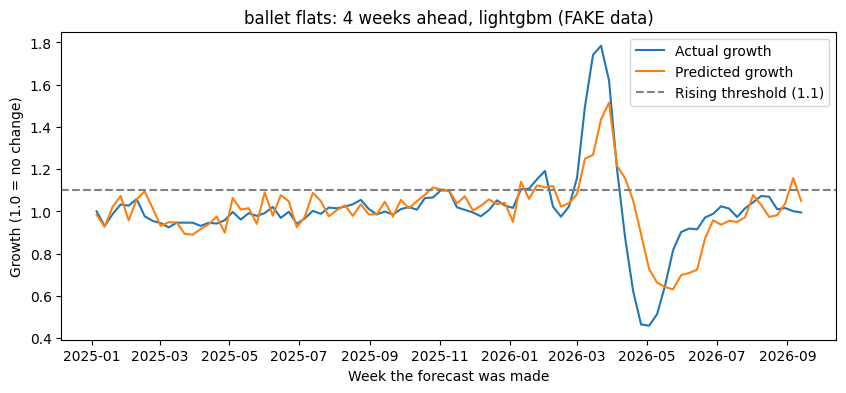

In [4]:
style, horizon, model = "ballet flats", 4, "lightgbm"
one = df[(df["item"] == style) & (df["horizon"] == horizon) & (df["model"] == model)]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(one["origin"], one["actual_growth"], label="Actual growth")
ax.plot(one["origin"], one["predicted_growth"], label="Predicted growth")
ax.axhline(RISING_THRESHOLD, linestyle="--", color="grey", label=f"Rising threshold ({RISING_THRESHOLD})")
ax.set_title(f"{style}: {horizon} weeks ahead, {model} (FAKE data)")
ax.set_xlabel("Week the forecast was made")
ax.set_ylabel("Growth (1.0 = no change)")
ax.legend()
plt.show()